# [Lab Session 3](fourier.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.transform import resize

**[Task 1 (a).]()** Load the first image, resize it to (256, 256) and display it.


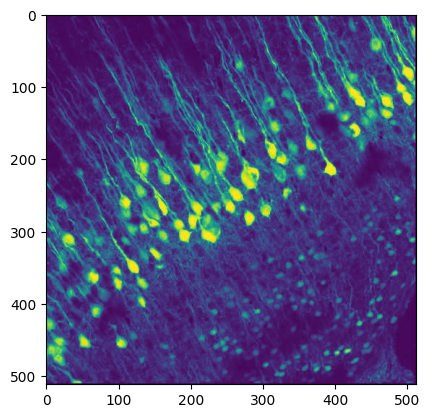

In [5]:
cell_img = plt.imread('data/cells.png')
cell_image = resize(cell_img, (256, 256))
plt.figure()
plt.imshow(cell_img)

**[Task 1 (b).]()** Apply the fast Fourier transform and check the data type of the result.


In [7]:
cell_ft = np.fft.fft2(cell_img)
print(cell_ft.dtype)

complex128


**[Task 1 (c).]()** Extract the phase and amplitude and display them.


In [15]:
amplitude = np.abs(cell_ft)
phase = np.angle(cell_ft)

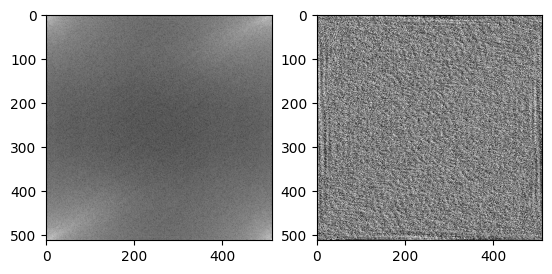

In [16]:
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude), 'gray')
plt.subplot(1, 2, 2)
plt.imshow(phase, 'gray')

**[Task 1 (d).]()** Do a shift so that zero is displayed in the center of the image and show amplitude and phase again.


Text(0.5, 1.0, 'Phase (verschoben)')

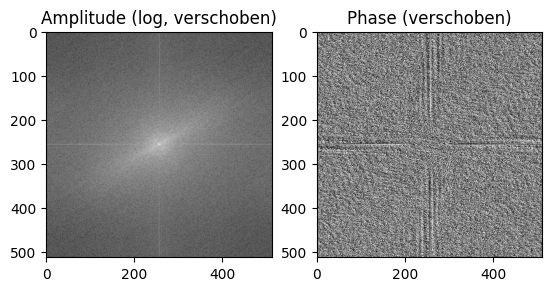

In [19]:

cell_ft_shift = np.fft.fftshift(cell_ft)

amplitude_shift = np.abs(cell_ft_shift)
phase_shift = np.angle(cell_ft_shift)
plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(amplitude_shift), 'gray')
plt.title('Amplitude (log, verschoben)')
plt.subplot(1, 2, 2)
plt.imshow(phase_shift, 'gray')
plt.title('Phase (verschoben)')

**[Task 1 (e).]()** Apply the inverse FFT and display the restored image.


Text(0.5, 1.0, 'Wiederhergestelltes Bild')

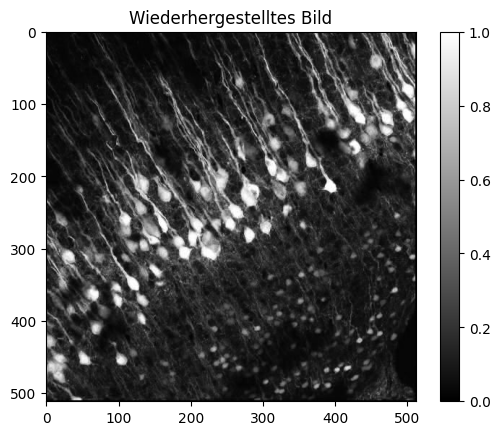

In [20]:
cell_restored = np.fft.ifft2(np.fft.ifftshift(cell_ft_shift)).real

plt.figure()
plt.imshow(cell_restored, 'gray')
plt.colorbar()
plt.title('Wiederhergestelltes Bild')


---


**[Task 2 (a).]()** Load the brain MR image.


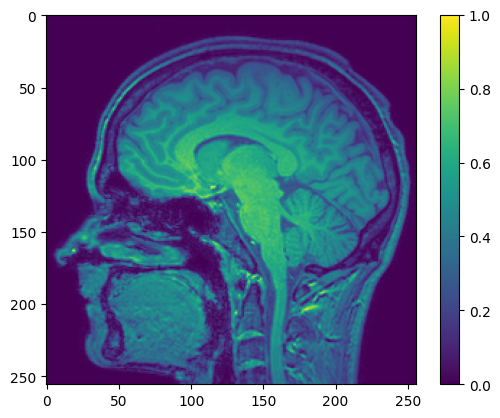

In [35]:
brain_img = plt.imread('data/brain_mri.png')
plt.figure()
plt.imshow(brain_img)
plt.colorbar()

**[Task 2 (b).]()** Apply the FFT, do a shift, extract amplitude and phase.


Text(0.5, 1.0, 'Phase')

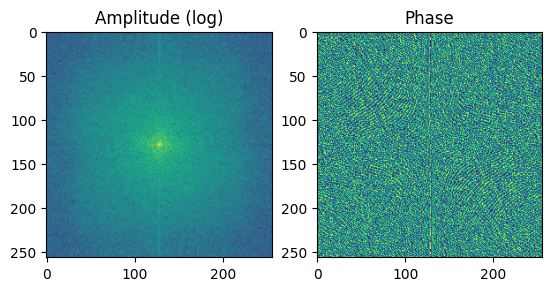

In [36]:
brain_ft_shift = np.fft.fftshift(np.fft.fft2(brain_img))

brain_amplitude_shift = np.abs(brain_ft_shift)
brain_phase_shift = np.angle(brain_ft_shift)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(brain_amplitude_shift))
plt.title('Amplitude (log)')
plt.subplot(1, 2, 2)
plt.imshow(brain_phase_shift)
plt.title('Phase')


In [37]:
def to_complex_array(amplitude_array, phase_array):
    return amplitude_array * np.exp(1j * phase_array)

**[Task 2 (c).]()** Merge the amplitude of the brain MR image and the phase of cell image. Do the IFFT and display the resulting image.


(256, 256) (256, 256)


Text(0.5, 1.0, 'Amplitude Gehirn + Phase Zelle')

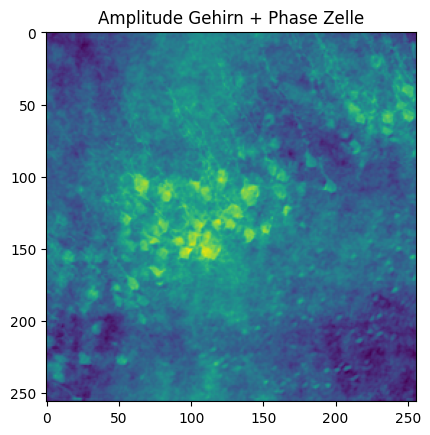

In [41]:
cell_img = resize(cell_img, (256, 256))

cell_ft_shift = np.fft.fftshift(np.fft.fft2(cell_img))
amplitude_shift = np.abs(cell_ft_shift)
phase_shift = np.angle(cell_ft_shift)

print(cell_img.shape, brain_img.shape)

merged1 = to_complex_array(brain_amplitude_shift, phase_shift)
merged1_img = np.fft.ifft2(np.fft.ifftshift(merged1)).real

plt.figure()
plt.imshow(merged1_img)
plt.title('Amplitude Gehirn + Phase Zelle')


**[Task 2 (d).]()** Repeat this with the amplitude of the cells and the phase of the brain.


(256, 256) (256, 256)


Text(0.5, 1.0, 'Amplitude Zelle + Phase Gehirn')

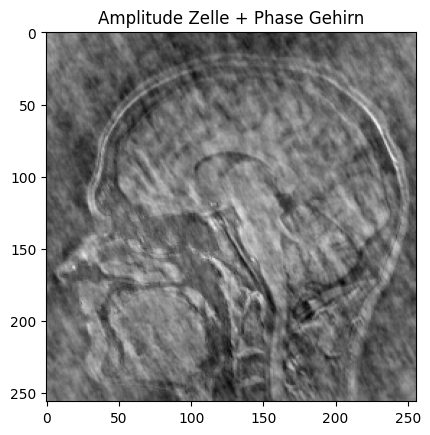

In [42]:
cell_img = resize(cell_img, (256, 256))

cell_ft_shift = np.fft.fftshift(np.fft.fft2(cell_img))
amplitude_shift = np.abs(cell_ft_shift)
phase_shift = np.angle(cell_ft_shift)

print(cell_img.shape, brain_img.shape)

merged2 = to_complex_array(amplitude_shift, brain_phase_shift)
merged2_img = np.fft.ifft2(np.fft.ifftshift(merged2)).real

plt.figure()
plt.imshow(merged2_img, 'gray')
plt.title('Amplitude Zelle + Phase Gehirn')

---


**[Task 3 (a).]()** Create a lowpass filter mask.


Text(0.5, 1.0, 'Tiefpass-Maske')

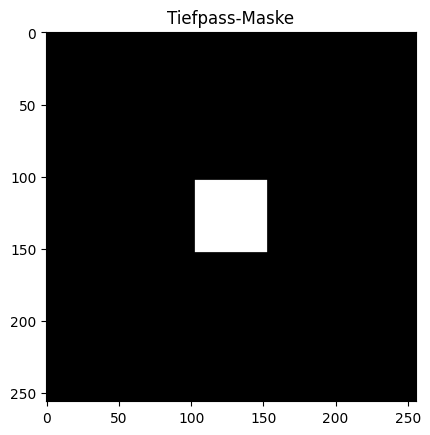

In [43]:
filter_window_size = 50
M, N = brain_img.shape
cx, cy = M // 2, N // 2
half = filter_window_size // 2

lowpass = np.zeros((M, N))
lowpass[cx - half : cx + half, cy - half : cy + half] = 1

plt.figure()
plt.imshow(lowpass, 'gray')
plt.title('Tiefpass-Maske')

Text(0.5, 1.0, 'Hochpass-Maske')

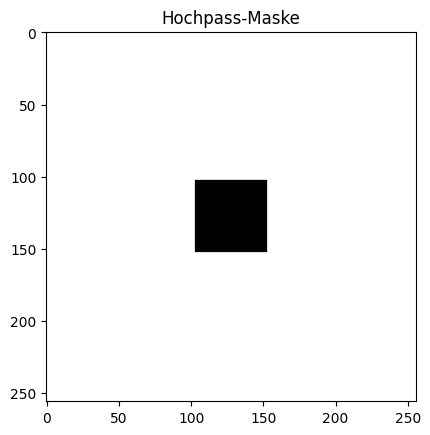

**[Task 3 (b).]()** Create a highpass filter maks.


Text(0.5, 1.0, 'Hochpass-Maske')

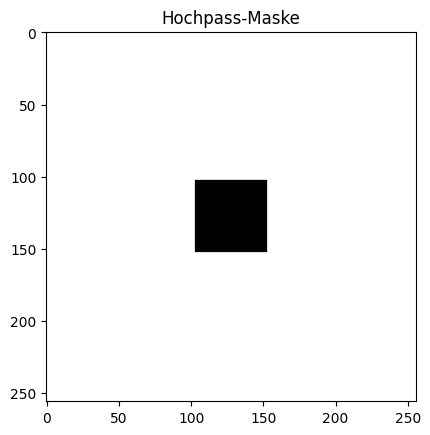

In [45]:
highpass = 1 - lowpass

plt.figure()
plt.imshow(highpass, 'gray')
plt.title('Hochpass-Maske')

**[Task 3 (c).]()** Apply the lowpass and highpass filter mask to the amplitude of the brain and display the results.


Text(0.5, 1.0, 'Hochpass')

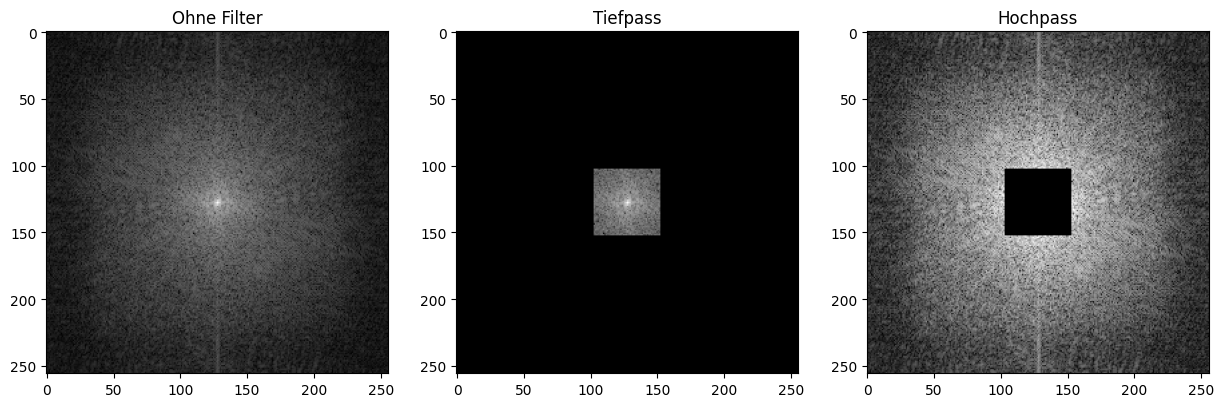

In [46]:
amp_low = brain_amplitude_shift * lowpass
amp_high = brain_amplitude_shift * highpass

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(np.log(1 + brain_amplitude_shift), 'gray')
plt.title('Ohne Filter')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + amp_low), 'gray')
plt.title('Tiefpass')
plt.subplot(1, 3, 3)
plt.imshow(np.log(1 + amp_high), 'gray')
plt.title('Hochpass')


**[Task 3 (d).]()** Apply the mask to the amplitude, merge the result with the phase and restore the image.


Text(0.5, 1.0, 'Hochpass')

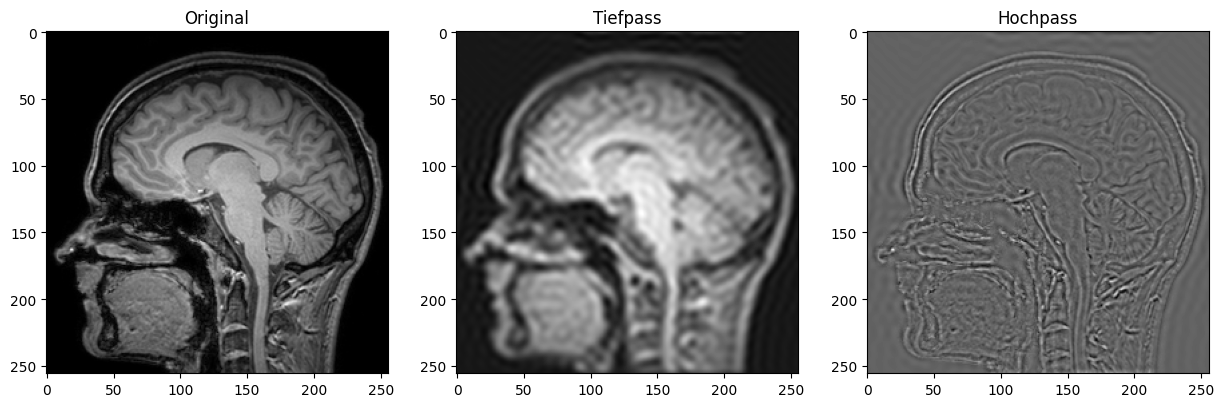

In [ ]:
low_img = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amp_low, brain_phase_shift))).real
high_img = np.fft.ifft2(np.fft.ifftshift(to_complex_array(amp_high, brain_phase_shift))).real

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(brain_img, 'gray')
plt.title('Original')

plt.subplot(1, 3, 2)
plt.imshow(low_img, 'gray')
plt.title('Tiefpass')
plt.subplot(1, 3, 3)

plt.imshow(high_img, 'gray')
plt.title('Hochpass')


---


**[Task 4 (a).]()** Implement a function that computes the 2D-DFT.


In [48]:
def my_dft(img):
    M, N = img.shape
    dft = np.zeros(img.shape, dtype=complex)

    x = np.arange(M).reshape(M, 1)  # Spalte: 0 ... M-1
    y = np.arange(N).reshape(1, N)  # Zeile:  0 ... N-1

    for u in range(M):
        for v in range(N):
            dft[u, v] = (img * np.exp(-2j * np.pi * (u * x / M + v * y / N))).sum() / (M * N)

    return dft

**[Task 4 (b).]()** Implement a function that computes the 2D-IDFT.


In [49]:
def my_idft(dft):
    M, N = dft.shape
    idft = np.zeros(dft.shape, dtype=complex)

    x = np.arange(M).reshape(M, 1)
    y = np.arange(N).reshape(1, N)

    for u in range(M):
        for v in range(N):
            idft[u, v] = (dft * np.exp(2j * np.pi * (u * x / M + v * y / N))).sum()

    return idft


Due to high computational costs, we need to resize the image.


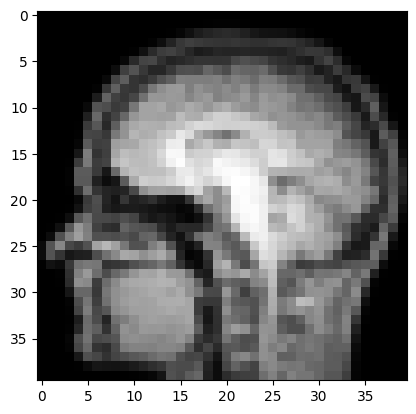

In [50]:
test_img = resize(brain_img, (40, 40))
plt.imshow(test_img, 'gray')

**[Task 4 (c).]()** Apply your DFT implementation to the image and display amplitude and phase.


Text(0.5, 1.0, 'Phase')

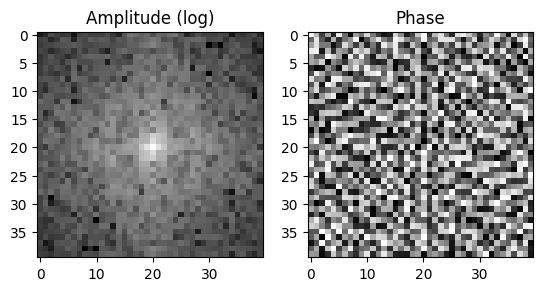

In [51]:
own_dft = my_dft(test_img)
own_dft_shift = np.fft.fftshift(own_dft)

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(np.log(np.abs(own_dft_shift)), 'gray')
plt.title('Amplitude (log)')
plt.subplot(1, 2, 2)
plt.imshow(np.angle(own_dft_shift), 'gray')
plt.title('Phase')


**[Task 4 (d).]()** Reconstruct the image using your IDFT implementation and display it.


Text(0.5, 1.0, 'Eigene IDFT')

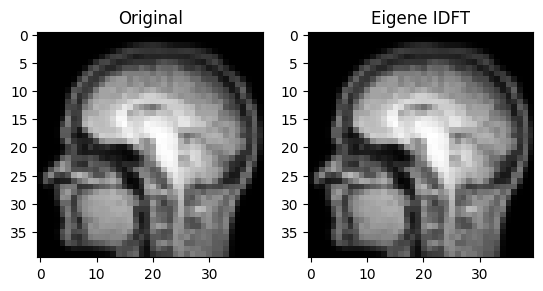

In [52]:
restored = my_idft(own_dft).real

plt.figure()
plt.subplot(1, 2, 1)
plt.imshow(test_img, 'gray')
plt.title('Original')
plt.subplot(1, 2, 2)
plt.imshow(restored, 'gray')
plt.title('Eigene IDFT')


**[Task 4 (e).]()** Compare your result to the result of numpy's FFT


In [53]:
np_fft = np.fft.fft2(test_img, norm='forward')
print(np.allclose(own_dft, np_fft))  # sollte True sein


True


**[Task 4 (f).]()** Round the arrays and compare them again.


In [54]:
print('Mittlere Abweichung:', np.mean(np.abs(own_dft - np_fft)))

decimals = 5  # anpassen
print((np.round(own_dft, decimals) == np.round(np_fft, decimals)).all())

for decimals in range(1, 17):
    match = (np.round(own_dft, decimals) == np.round(np_fft, decimals)).all()
    print(decimals, match)


Mittlere Abweichung: 7.525284431170575e-17
True
1 True
2 True
3 True
4 True
5 True
6 True
7 True
8 True
9 True
10 True
11 True
12 True
13 False
14 False
15 False
16 False


**[Task 4 (g).]()** Compare the run times of the two algorithms (your DFT and numpy's FFT)


In [55]:
%timeit my_dft(test_img)

%timeit np.fft.fft2(test_img, norm='forward')


125 ms ± 17.2 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)
47.7 μs ± 16.6 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)
